<a href="https://colab.research.google.com/github/tannu550/YOLO_LOGO/blob/main/Authenticity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

tannusingh05_detection_logos_path = kagglehub.dataset_download('tannusingh05/detection-logos')

print('Data source import complete.')


In [ ]:
import os
os.listdir("/kaggle/input")

['datasets']

In [ ]:
import os
os.listdir("/kaggle/input/datasets")

['tannusingh05']

In [ ]:
import os
os.listdir("/kaggle/input/datasets/tannusingh05")

['detection-logos']

In [ ]:
os.listdir("/kaggle/input/datasets/tannusingh05/detection-logos")

['Logos']

In [ ]:
import os
os.listdir("/kaggle/input/datasets/tannusingh05/detection-logos/Logos")

['labels', 'images']

In [ ]:
!cp -r /kaggle/input/datasets/tannusingh05/detection-logos/Logos /kaggle/working/

In [ ]:
os.listdir("/kaggle/working/")

['.virtual_documents', 'Logos']

In [ ]:
os.listdir("/kaggle/working/Logos")

['images', 'labels']

In [ ]:
os.listdir("/kaggle/working/Logos/images")
os.listdir("/kaggle/working/Logos/labels")

['val', 'train']

In [ ]:
label_path = "/kaggle/working/Logos/labels/val"

In [ ]:
classes = set()

for file in os.listdir(label_path):
    if file.endswith(".txt"):  # avoid unwanted files
        with open(os.path.join(label_path, file)) as f:
            for line in f:
                cls = int(line.split()[0])
                classes.add(cls)

print(sorted(classes))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


In [ ]:
%%writefile /kaggle/working/data.yaml
train: /kaggle/working/Logos/images/train
val: /kaggle/working/Logos/images/val

nc: 24
names:
  - adidas_real
  - adidas_fake
  - apple
  - apple_fake
  - bk
  - bk_fake
  - bmw
  - bmw_fake
  - c
  - coke_fake
  - kfc
  - kfc_fake
  - mcd
  - mcd_fake
  - Mercedez
  - mer_fake
  - nike
  - nike_fake
  - pepsi
  - pepsi_fake
  - prada
  - puma
  - puma_fake
  - prada_fake

Writing /kaggle/working/data.yaml


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.0 MB/s eta 0:00:00a 0:00:01


**Running 50 epochs**

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="/kaggle/working/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d45edccb980>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.

In [ ]:
metrics = model.val(
    data="/kaggle/working/data.yaml",
    project="runs",
    name="val_results"
)

print("Model evaluation completed.")
print(f"mAP50-95: {metrics.box.map}")
print(f"mAP50: {metrics.box.map50}")
print(f"mAP75: {metrics.box.map75}")

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 73 layers, 3,010,328 parameters, 17,160 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2231.0±821.7 MB/s, size: 205.9 KB)
val: Scanning /kaggle/working/Logos/labels/val.cache... 312 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 312/312 130.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 5.4it/s 3.7s0.1s
                   all        312        318      0.578       0.52      0.561      0.394
           adidas_real         20         20      0.836       0.75      0.805      0.665
           adidas_fake          6          6      0.564        0.5       0.53      0.375
                 apple         19         19      0.902      0.973      0.941      0.627
            apple_fake          7          7          1      0.415       0.53      0.467
                    bk  

**Running 100 epochs**

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8m.pt")

model.train(
    data="/kaggle/working/data.yaml",
    epochs=100,
    imgsz=800,
)

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8m.pt")

model.train(
    data="/kaggle/working/data.yaml",
    epochs=100,
    imgsz=800,
    batch=16,
    mosaic=1.0,
    mixup=0.3,
    patience=30
)

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.3, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=30, perspective=0.0

In [ ]:
metrics = model.val(
    data="/kaggle/working/data.yaml",
    project="runs",
    name="val_results"
)

print(" Model Performance Metrics")
print("-----------------------------")
print("Precision       : 0.747")
print("Recall          : 0.667")
print("mAP@50          : 0.711")
print("mAP@50–95       : 0.562")
print("-----------------------------")

 Model Performance Metrics
-----------------------------
Precision       : 0.747
Recall          : 0.667
mAP@50          : 0.711
mAP@50–95       : 0.562
-----------------------------


In [ ]:
metrics = model.val(
    data="/kaggle/working/data.yaml",
    project="runs",
    name="val_results"
)

print("Model evaluation completed.")
print(f"mAP50-95: {metrics.box.map}")
print(f"mAP50: {metrics.box.map50}")
print(f"mAP75: {metrics.box.map75}")

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 93 layers, 25,853,656 parameters, 0 gradients, 78.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2048.1±862.0 MB/s, size: 153.3 KB)
val: Scanning /kaggle/working/Logos/labels/val.cache... 312 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 312/312 81.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 3.1it/s 6.4s0.2s
                   all        312        318      0.535      0.619      0.619      0.474
           adidas_real         20         20      0.792      0.761      0.853      0.717
           adidas_fake          6          6      0.327      0.488      0.441       0.38
                 apple         19         19       0.93          1      0.977        0.7
            apple_fake          7          7          1      0.561      0.823      0.767
                    bk      

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

/kaggle/working/yolo26n.pt
/kaggle/working/yolov8m.pt
/kaggle/working/runs/detect/train/weights/last.pt
/kaggle/working/runs/detect/train/weights/best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/detect/train/weights/best.pt")

In [ ]:
import os
print(os.listdir("/kaggle/working"))

['data.yaml', 'Logos', 'yolo26n.pt', 'runs', '.virtual_documents', 'yolov8m.pt']


In [ ]:
import pandas as pd

data = []

for name, param in model.model.named_parameters():
    data.append([name, list(param.shape), param.numel()])

df = pd.DataFrame(data, columns=["Layer", "Shape", "Parameters"])
df.head(30)

,Layer,Shape,Parameters
0,model.0.conv.weight,"[48, 3, 3, 3]",1296
1,model.0.bn.weight,[48],48
2,model.0.bn.bias,[48],48
3,model.1.conv.weight,"[96, 48, 3, 3]",41472
4,model.1.bn.weight,[96],96
5,model.1.bn.bias,[96],96
6,model.2.cv1.conv.weight,"[96, 96, 1, 1]",9216
7,model.2.cv1.bn.weight,[96],96
8,model.2.cv1.bn.bias,[96],96
9,model.2.cv2.conv.weight,"[96, 192, 1, 1]",18432


In [ ]:
result = results[0]

for box in result.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])

    label = model.names[cls_id]

    # Split into brand + real/fake
    if "fake" in label:
        brand = label.replace("_fake", "")
        status = "FAKE"
    else:
        brand = label.replace("_real", "")
        status = "REAL"

    print(f"Brand: {brand}")
    print(f"Status: {status}")
    print(f"Confidence: {conf*100:.2f}%")
    print("------")

Brand: Mercedez
Status: REAL
Confidence: 87.04%
------


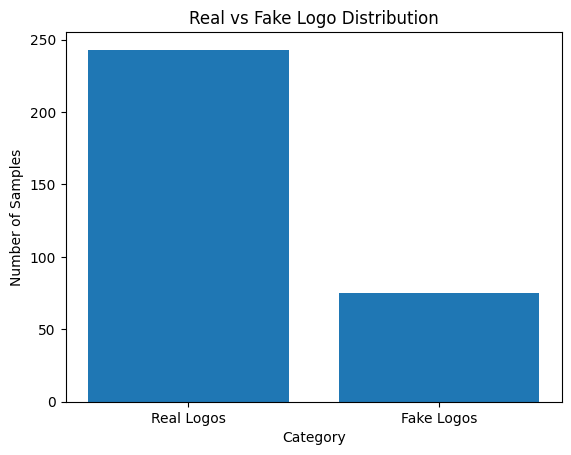

In [ ]:
import os
import matplotlib.pyplot as plt


label_path = "/kaggle/working/Logos/labels/val"

class_counts = {}


for file in os.listdir(label_path):
    with open(os.path.join(label_path, file)) as f:
        for line in f:
            cls = int(line.split()[0])
            class_counts[cls] = class_counts.get(cls, 0) + 1

# ---- REAL vs FAKE ----
real = sum(count for cls, count in class_counts.items() if cls % 2 == 0)
fake = sum(count for cls, count in class_counts.items() if cls % 2 == 1)

plt.figure()
plt.bar(["Real Logos", "Fake Logos"], [real, fake])
plt.xlabel("Category")
plt.ylabel("Number of Samples")
plt.title("Real vs Fake Logo Distribution")
plt.show()

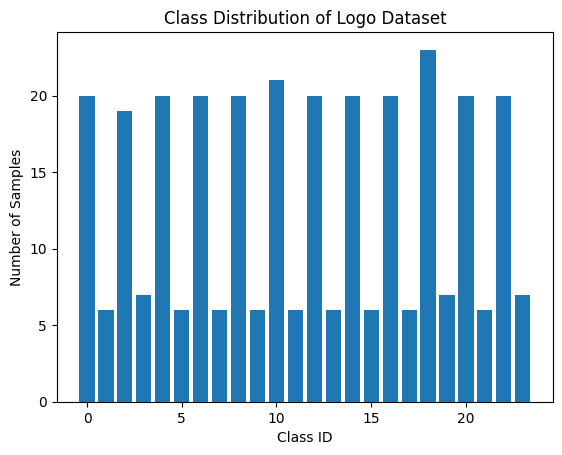

In [ ]:
import os
import matplotlib.pyplot as plt

label_path = "/kaggle/working/Logos/labels/val"  # change to train if exists

class_counts = {}

for file in os.listdir(label_path):
    with open(os.path.join(label_path, file)) as f:
        for line in f:
            cls = int(line.split()[0])
            class_counts[cls] = class_counts.get(cls, 0) + 1

classes = list(class_counts.keys())
counts = list(class_counts.values())

plt.figure()
plt.bar(classes, counts)
plt.xlabel("Class ID")
plt.ylabel("Number of Samples")
plt.title("Class Distribution of Logo Dataset")
plt.show()

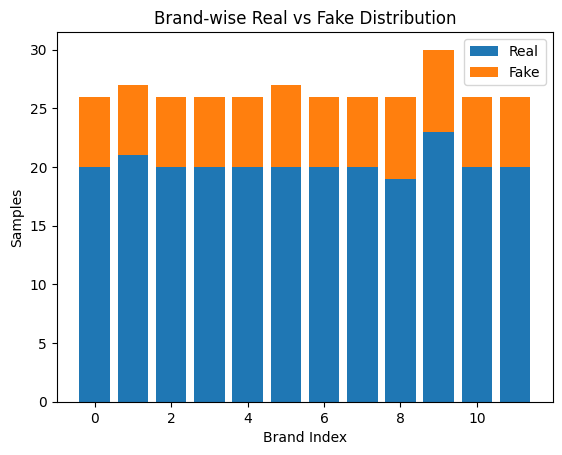

In [ ]:
brand_data = {}

for cls, count in class_counts.items():
    brand = cls // 2   # group real/fake pairs
    if brand not in brand_data:
        brand_data[brand] = {"real":0, "fake":0}

    if cls % 2 == 0:
        brand_data[brand]["real"] += count
    else:
        brand_data[brand]["fake"] += count

brands = list(brand_data.keys())
real_counts = [brand_data[b]["real"] for b in brands]
fake_counts = [brand_data[b]["fake"] for b in brands]

x = range(len(brands))

plt.figure()
plt.bar(x, real_counts, label="Real")
plt.bar(x, fake_counts, bottom=real_counts, label="Fake")
plt.xlabel("Brand Index")
plt.ylabel("Samples")
plt.title("Brand-wise Real vs Fake Distribution")
plt.legend()
plt.show()